# Data

## Loans issued in 2007-2013

In [1]:
import pandas as pd

years  = [str(year) for year in range(2007, 2014)]
chunks = pd.read_csv('data/accepted_2007_to_2018Q4.csv.gz',
                     usecols=['loan_amnt', 'term', 'emp_length', 'home_ownership', 'annual_inc', 'verification_status',
                              'dti', 'delinq_2yrs', 'open_acc', 'pub_rec', 'revol_bal', 'revol_util',
                              'earliest_cr_line', 'issue_d', 'loan_status', 'sub_grade'],
                     chunksize=100000)
df = pd.concat(chunk[chunk.issue_d.str[-4:].isin(years)] for chunk in chunks)
df['issue_d'] = pd.to_datetime(df.issue_d, format='%b-%Y')
df

,loan_amnt,term,sub_grade,emp_length,home_ownership,annual_inc,verification_status,issue_d,loan_status,dti,delinq_2yrs,earliest_cr_line,open_acc,pub_rec,revol_bal,revol_util
1611879,5000.0,36 months,B2,10+ years,RENT,24000.0,Verified,2011-12-01,Fully Paid,27.65,0.0,Jan-1985,3.0,0.0,13648.0,83.7
1611880,2500.0,60 months,C4,< 1 year,RENT,30000.0,Source Verified,2011-12-01,Charged Off,1.00,0.0,Apr-1999,3.0,0.0,1687.0,9.4
1611881,2400.0,36 months,C5,10+ years,RENT,12252.0,Not Verified,2011-12-01,Fully Paid,8.72,0.0,Nov-2001,2.0,0.0,2956.0,98.5
1611882,10000.0,36 months,C1,10+ years,RENT,49200.0,Source Verified,2011-12-01,Fully Paid,20.00,0.0,Feb-1996,10.0,0.0,5598.0,21.0
1611883,3000.0,60 months,B5,1 year,RENT,80000.0,Source Verified,2011-12-01,Fully Paid,17.94,0.0,Jan-1996,15.0,0.0,27783.0,53.9
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1939374,20500.0,36 months,D2,7 years,RENT,60000.0,Source Verified,2012-01-01,Fully Paid,16.40,1.0,Oct-1988,10.0,0.0,15417.0,58.4
1939375,15000.0,36 months,C4,3 years,RENT,57600.0,Source Verified,2012-01-01,Fully Paid,8.35,2.0,Jan-2004,18.0,0.0,8897.0,33.1
1939376,35000.0,36 months,C5,3 years,MORTGAGE,160000.0,Source Verified,2012-01-01,Fully Paid,4.90,0.0,Sep-2000,9.0,0.0,23665.0,62.4
1939377,12000.0,36 months,D1,NaN,MORTGAGE,35000.0,Source Verified,2012-01-01,Charged Off,12.93,0.0,Aug-2001,14.0,0.0,15006.0,93.2


In [2]:
df.loan_status.value_counts()

loan_status
Fully Paid                                             192619
Charged Off                                             35338
Does not meet the credit policy. Status:Fully Paid       1988
Does not meet the credit policy. Status:Charged Off       761
Current                                                     6
Late (31-120 days)                                          3
In Grace Period                                             1
Name: count, dtype: int64

## The default variable

In [3]:
default_map = {'Fully Paid'                                          : 0,
               'Does not meet the credit policy. Status:Fully Paid'  : 0,
               'Charged Off'                                         : 1,
               'Default'                                             : 1,
               'Does not meet the credit policy. Status:Charged Off' : 1}

df = df[df.loan_status.isin(default_map)].copy()
df['default'] = df.loan_status.map(default_map)
df.default.value_counts()

default
0    194607
1     36099
Name: count, dtype: int64

## The 13 variables

In [4]:
df['term']                = df.term.str.extract(r'(\d+)', expand=False).astype(float)
df['emp_length']          = df.emp_length.str.replace('< 1', '0').str.extract(r'(\d+)', expand=False).astype(float)
df['home_ownership']      = df.home_ownership.isin(['OWN', 'MORTGAGE']).astype(int)
df['verification_status'] = df.verification_status.isin(['Verified', 'Source Verified']).astype(int)
df['revol_util']          = pd.to_numeric(df.revol_util.astype(str).str.rstrip('%'), errors='coerce')
df['earliest_cr_line']    = pd.to_datetime(df.earliest_cr_line, format='%b-%Y')
df['years_of_credit']     = (df.issue_d - df.earliest_cr_line).dt.days / 365.25

In [5]:
variables = ['loan_amnt', 'term', 'emp_length', 'home_ownership', 'annual_inc', 'verification_status', 'dti',
                            'delinq_2yrs', 'open_acc', 'pub_rec', 'revol_bal', 'revol_util', 'years_of_credit']

In [6]:
df[variables].describe().T

,count,mean,std,min,25%,50%,75%,max
loan_amnt,230706.0,13752.244740,8089.353164,500.000000,7500.00000,12000.000000,19125.000000,3.500000e+04
term,230706.0,41.750696,10.244347,36.000000,36.00000,36.000000,36.000000,6.000000e+01
emp_length,221707.0,5.872417,3.595245,0.000000,3.00000,6.000000,10.000000,1.000000e+01
home_ownership,230706.0,0.583726,0.492941,0.000000,0.00000,1.000000,1.000000,1.000000e+00
annual_inc,230702.0,71661.661108,54309.236476,1896.000000,45000.00000,61000.000000,85500.000000,7.141778e+06
verification_status,230706.0,0.663702,0.472443,0.000000,0.00000,1.000000,1.000000,1.000000e+00
dti,230706.0,16.380185,7.580627,0.000000,10.71000,16.130000,21.810000,3.499000e+01
delinq_2yrs,230677.0,0.223559,0.673429,0.000000,0.00000,0.000000,0.000000,2.900000e+01
open_acc,230677.0,10.695509,4.631971,0.000000,7.00000,10.000000,13.000000,6.200000e+01
pub_rec,230677.0,0.097357,0.382309,0.000000,0.00000,0.000000,0.000000,5.400000e+01


## Missing values

In [7]:
df[variables + ['sub_grade']].isna().sum()

loan_amnt                 0
term                      0
emp_length             8999
home_ownership            0
annual_inc                4
verification_status       0
dti                       0
delinq_2yrs              29
open_acc                 29
pub_rec                  29
revol_bal                 0
revol_util              215
years_of_credit          29
sub_grade                 0
dtype: int64

In [8]:
df = df.dropna(subset=variables + ['sub_grade'])
len(df)

221498

## Development and holdout sets

In [9]:
df['year'] = df.issue_d.dt.year
df.groupby('year').default.agg(['count', 'mean'])

,count,mean
year,,
2007,571,0.267951
2008,2381,0.206636
2009,5265,0.136752
2010,12164,0.136550
2011,20955,0.149797
2012,51398,0.160629
2013,128764,0.154003


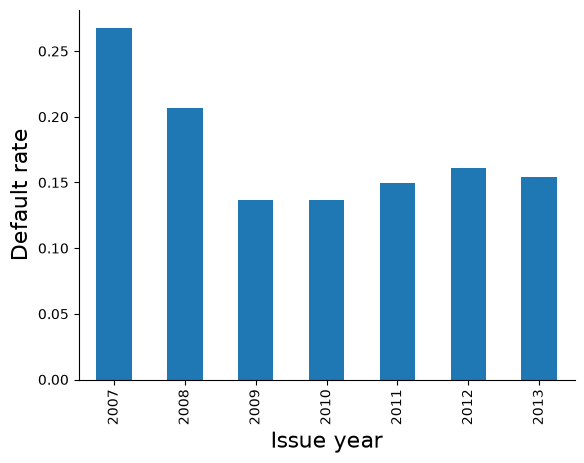

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

df.groupby('year').default.mean().plot(kind='bar')

plt.xlabel('Issue year', fontsize=16)
plt.ylabel('Default rate', fontsize=16)
sns.despine()
plt.savefig('figures/default_rate_by_year.png', bbox_inches='tight')

In [11]:
df[df.year <= 2012][variables + ['default', 'sub_grade']].to_csv('data/credit_dev.csv', index=False)
df[df.year == 2013][variables + ['default', 'sub_grade']].to_csv('data/credit_holdout.csv', index=False)